In [5]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, aggregate_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr
from matplotlib.projections import PolarAxes
from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

# Loading data

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
TEs = df_TEs.index.values

In [3]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [71]:
baseline = 'ssp534-over'
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   
ds_D = [xr.open_zarr(folder+par_files[i]+'.zarr') for i in range(6)]
pars = [ds.parameter.to_numpy() for ds in ds_D]
D = [ds.risk.to_numpy() for ds in ds_D]
popt = np.array([float(s.split("= ",1)[1]) for s in [ds_D[1].description.splitlines()[1]] + ds_D[0].description.splitlines()[1:]])

r_data = np.array([critical_parameter(D[i],pars[i],axis=0) for i in range(len(popt))])
#np.array([np.max(np.squeeze(local_safety(D[i]))*pars[i].reshape(len(pars[i]),1),axis=0) for i in range(len(popt))])

# old plotting

In [ ]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,2.5+.1,step=0.5),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,2.5+.1,step=0.5)]
ylims=[(-1,5), (-0.5,2.5), (-50,200), (-50,200), (-50,200), (-0.5,2.5)]
N=r_data.shape[0]
outer_width = 1.1*180/N
inner_width = 180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(9,9))
radar = Radar(fig, titles, rotate_labels=True, wedge_width = width, with_rlabels=True, ylims=ylims, rticks=rticks)

sim2ax_reorder = [1,0,3,4,5,2]
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
for i in range(r_data.shape[1]):
    angles = np.array(radar.angles) + width*(i/r_data.shape[1] - 1/2 + 1/r_data.shape[1]/2)
    radar.bar(popt-r_data[sim2ax_reorder,i],
              color=colors[i],
              width=np.deg2rad(width/r_data.shape[1]), 
              angles=np.deg2rad(angles))
# radar.bar(popt[sim2ax_reorder],color='r',width=np.deg2rad(inner_width))

# best plots

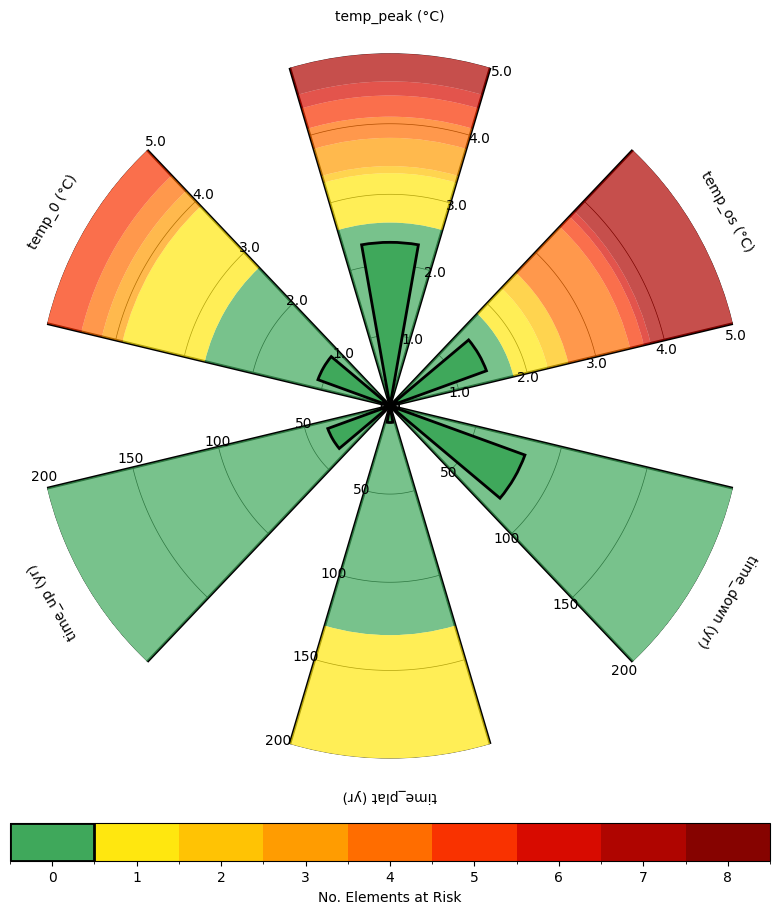

In [72]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=r_data.shape[0]
outer_width = 1.1*180/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
r_noreef = np.delete(r_data, 6, axis=1)
r_sort=np.sort(r_noreef,axis=1)
no_breached = np.sum(popt.reshape(r_sort.shape[0],1) > r_sort,axis=1)
nb = no_breached[0]
hatches=['.','.'] 

c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+r_sort.shape[1]]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=len(c_list))
bounds = np.arange(-0.5,9,step=1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    r_plot = r_sort[sim2ax_reorder,:][j,:]

    radar.wedge_stacked_bar(ax,angle,r_plot,c_list=c_list)
    radar.wedge_stacked_bar(ax,angle,r_plot[:nb],c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k')
    if nb>0:
        bottom=r_plot[nb-1]
    else:
        bottom=0
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=[c_list[nb]],
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',bottom=bottom,lw=2)

fig.subplots_adjust(bottom=0.2)
# cbar_ax = fig.add_axes([0,-0.1,1,0.1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label='No. Elements at Risk',
                    ticks=np.arange(0,9))
rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')

# single metric at the total risk level

In [24]:
D_noreef = [np.delete(d,6,axis=2) for d in D]
TR = [d.max(axis=-1).mean(axis=(1,2)) for d in D_noreef]
r_TR = [np.max((tr<=0.1)*pars[i]) for i,tr in enumerate(TR)]
print(r_TR)

[np.float64(0.0), np.float64(1.7000000000000002), np.float64(1.9000000000000001), np.int64(0), np.int64(0), np.int64(0)]


(0.0, 1.0)

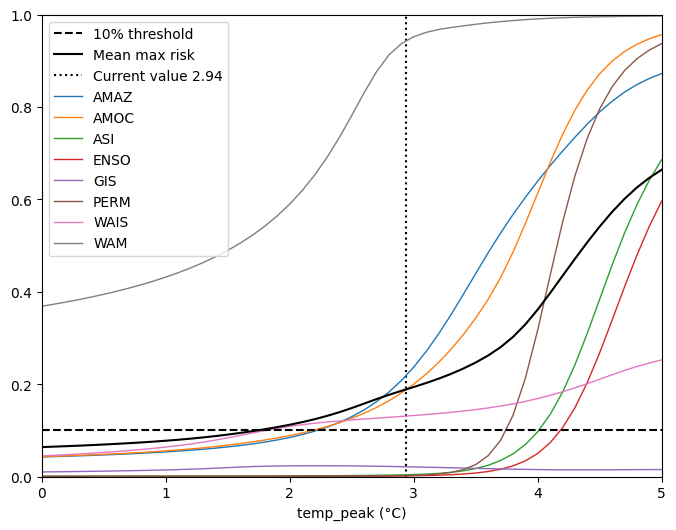

In [28]:
fig = plt.figure(figsize=(8,6))
par_names = ['temp_0 (°C)', 'temp_peak (°C)', 'temp_os (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)']

i = 1
# plt.plot(pars[i],D_noreef[i].mean(axis=(1,2)).max(axis=-1), label = 'mean, max',c='b')
plt.plot(pars[i][[0,-1]], [0.1]*2,c='k',ls='--',label='10% threshold')
plt.plot(pars[i],D_noreef[i].max(axis=-1).mean(axis=(1,2)), label = 'Mean max risk',c='k')
plt.plot([popt[i]]*2,[0,1],c='k',ls=':',label='Current value %.2f'%popt[i],zorder=0)
# plt.plot(pars[i],D_noreef[i].max(axis=-1).mean(axis=(1,2))*D_noreef[i].shape[-2], label = 'Total max risk',c='k',ls='-.')
for j in range(D_noreef[i].shape[-2]):
    # plt.plot(pars[i],D_noreef[i].mean(axis=1).max(axis=-1)[:,j],c='b',lw=0.5)
    plt.plot(pars[i],D_noreef[i].max(axis=-1).mean(axis=1)[:,j],
             lw=1,label=np.delete(TEs,6,axis=0)[j],zorder=0)

plt.legend(ncols=1)
plt.xlabel(par_names[i])
plt.xlim(pars[i][[0,-1]])
plt.ylim(0,1)

(0.0, 5.0)

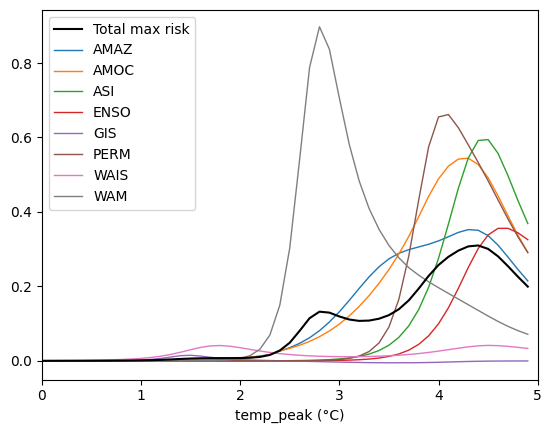

In [14]:
par_names = ['temp_0 (°C)', 'temp_peak (°C)', 'temp_os (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)']

i = 1
# plt.plot(pars[i],D_noreef[i].mean(axis=(1,2)).max(axis=-1), label = 'mean, max',c='b')
# plt.plot(pars[i][[0,-1]], [0.1]*2,c='k',ls='--',label='10% threshold')
plt.plot(pars[i][:-1], np.diff(D_noreef[i].max(axis=-1).mean(axis=(1,2)))/np.diff(pars[i]), 
         label = 'Total max risk',c='k')
for j in range(D_noreef[i].shape[-2]):
    # plt.plot(pars[i],D_noreef[i].mean(axis=1).max(axis=-1)[:,j],c='b',lw=0.5)
    plt.plot(pars[i][:-1], np.diff(D_noreef[i].max(axis=-1).mean(axis=1)[:,j])/np.diff(pars[i]),
             lw=1,label=np.delete(TEs,6,axis=0)[j],zorder=0)
plt.legend()
plt.xlabel(par_names[i])
plt.xlim(pars[i][[0,-1]])

In [ ]:
for j in range(D_noreef[0].shape[-2]):
    plt.plot

In [ ]:
r_TR = []

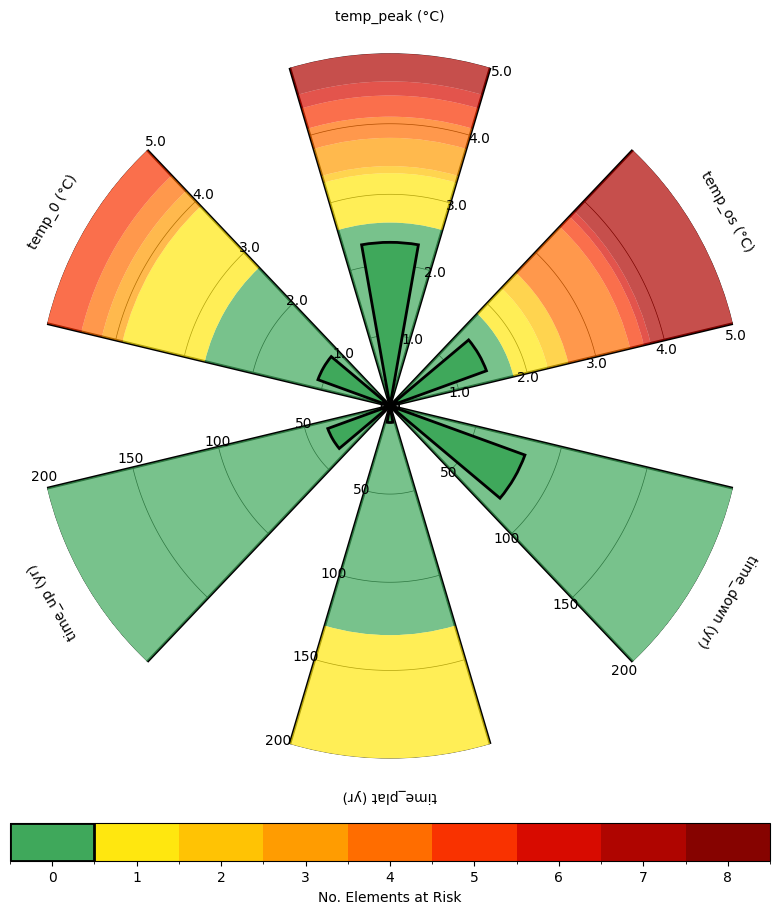

In [73]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=r_data.shape[0]
outer_width = 1.1*180/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
r_noreef = np.delete(r_data, 6, axis=1)
r_sort=np.sort(r_noreef,axis=1)
no_breached = np.sum(popt.reshape(r_sort.shape[0],1) > r_sort,axis=1)
nb = no_breached[0]
hatches=['.','.'] 

c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+r_sort.shape[1]]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=len(c_list))
bounds = np.arange(-0.5,9,step=1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    r_plot = r_sort[sim2ax_reorder,:][j,:]

    radar.wedge_stacked_bar(ax,angle,r_plot,c_list=c_list)
    radar.wedge_stacked_bar(ax,angle,r_plot[:nb],c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k')
    if nb>0:
        bottom=r_plot[nb-1]
    else:
        bottom=0
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=[c_list[nb]],
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',bottom=bottom,lw=2)

fig.subplots_adjust(bottom=0.2)
# cbar_ax = fig.add_axes([0,-0.1,1,0.1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label='No. Elements at Risk',
                    ticks=np.arange(0,9))
rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')

# polar bar charts of aggregate risk

In [74]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR = [np.array([aggregate_risk(D_noreef[i].mean(axis=1),k,axis=1) 
                     for k in range(D_noreef[i].shape[-2])]) 
           for i in tqdm.tqdm(range(len(popt)))]
R_data = np.array([np.max(pars[i].reshape(1,len(pars[i]),1)*(AR[i]<=0.1), axis=1) for i in range(6)])

100%|█████████████████████████████████████████████| 6/6 [00:00<00:00,  6.22it/s]


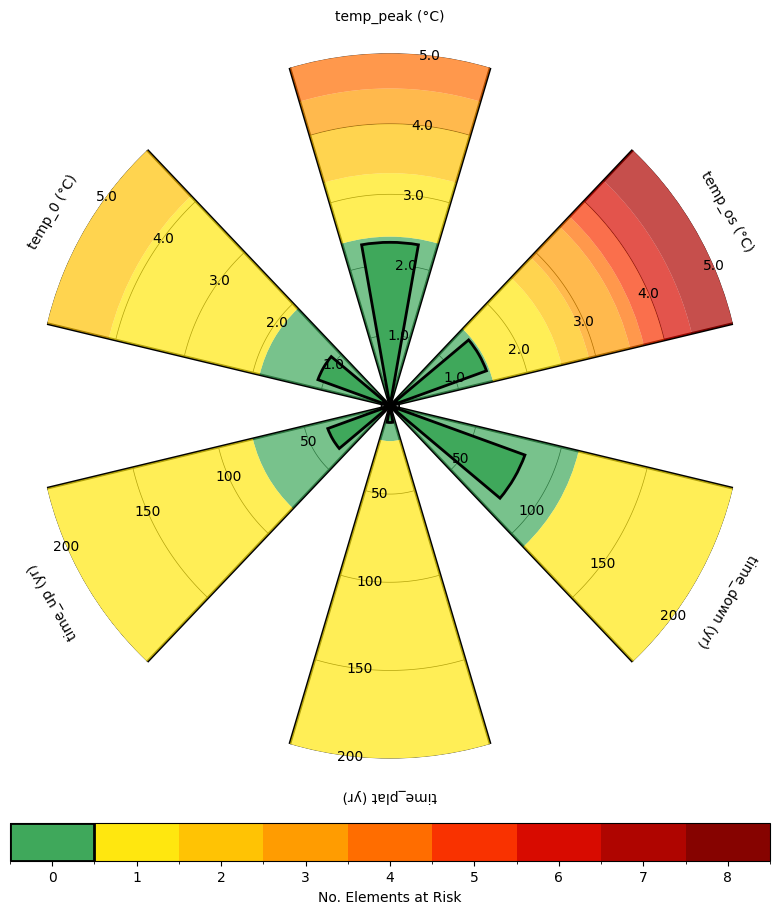

In [75]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=R_data.shape[0]
outer_width = 1.1*180/N#360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
# R_noreef = np.delete(r_data, 6, axis=1)
R_sort= R_data[:,:,-1]#np.sort(R_data,axis=1)
no_breached = np.sum(popt.reshape(R_sort.shape[0],1) > R_sort,axis=1)
nb = no_breached[0]
hatches=['.','.'] 

c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+r_sort.shape[1]]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=len(c_list))
bounds = np.arange(-0.5,9,step=1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    R_plot = R_sort[sim2ax_reorder,:][j,:]

    radar.wedge_stacked_bar(ax,angle,R_plot,c_list=c_list,zorder=0)
    radar.wedge_stacked_bar(ax,angle,R_plot[:nb],c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2)
    if nb>0:
        bottom=R_plot[nb-1]
    else:
        bottom=0
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=[c_list[nb]],
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',
                            bottom=bottom,
                            lw=2,zorder=1)

fig.subplots_adjust(bottom=0.2)
# cbar_ax = fig.add_axes([0,-0.1,1,0.1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label='No. Elements at Risk',
                    ticks=np.arange(0,9))
rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')

In [79]:
D_noreef[i].shape

(51, 500, 8, 286)

<>:9: SyntaxWarning: invalid escape sequence '\g'
<>:9: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_30933/3798454991.py:9: SyntaxWarning: invalid escape sequence '\g'
  axs[1].plot(pars[i], AR[i][k,:,-1],label='$\geq$%d'%(k+1),c=c_list[k+1])


Text(0.5, 0, 'temp_os (°C)')

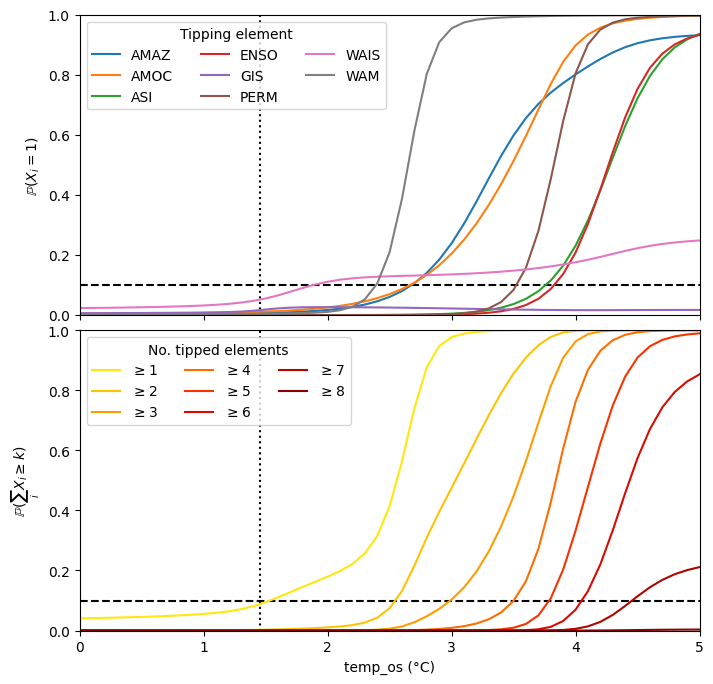

In [97]:
par_names = ['temp_0 (°C)', 'temp_peak (°C)', 'temp_os (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)']
i=2
fig,axs=plt.subplots(figsize=(8,8),nrows=2,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
for i_ax in range(2):
    axs[i_ax].plot(pars[i][[0,-1]], [0.1]*2,c='k',ls='--')
    axs[i_ax].plot([popt[i]]*2,[0,1],c='k',ls=':')
for k in range(D_noreef[i].shape[-2]):
    axs[1].plot(pars[i], AR[i][k,:,-1],label='$\geq$%d'%(k+1),c=c_list[k+1])
for j in range(D_noreef[i].shape[2]):
    axs[0].plot(pars[i], D_noreef[i].mean(axis=1)[:,j,-1],label=np.delete(TEs,6)[j])
    
axs[0].legend(ncols=3,title=r'Tipping element',loc='upper left')
axs[1].legend(ncols=3,title=r'No. tipped elements',loc='upper left')
axs[0].set_ylabel(r"$\mathbb{P}(X_i=1)$")
axs[1].set_ylabel(r'$\mathbb{P}(\sum_i X_i \geq k)$')
axs[0].set_xticks(rticks[np.argsort(sim2ax_reorder)[i]])

# axs[0].set_xticks(np.sort(list(rticks[np.argsort(sim2ax_reorder)[i]]) + [popt[i]]))

plt.xlim(pars[i][[0,-1]])
plt.ylim(0,1)
plt.xlabel(par_names[i])

In [54]:
np.argsort(sim2ax_reorder)

array([1, 0, 5, 2, 3, 4])

In [62]:
print(np.sort(list(rticks[1]) + [popt[i]]) )

[0.         1.         2.         3.         3.30206671 4.
 5.        ]


In [55]:
sim2ax_reorder

[1, 0, 3, 4, 5, 2]

In [51]:
rticks[[sim2ax_reorder]]

TypeError: list indices must be integers or slices, not list